# Pretrained ViT-B/16 for Skin Lesion Classification (HAM10000)

This notebook is the **pretrained companion** to `vit_ham10000.ipynb` (which trains a custom ViT from scratch).
Backbone: `torchvision.models.vit_b_16` with `ViT_B_16_Weights.DEFAULT` (ImageNet-1K supervised pretraining).

**What stays identical** to the from-scratch notebook:
- Lesion-id-stratified 70/15/15 split (same seed)
- 224x224 input, ImageNet normalisation
- Augmentation (flips, rotation, colour jitter, `RandomResizedCrop`)
- `SkinLesionDataset` returning `(img, stage1_label, stage2_label)`
- Weighted cross-entropy for class imbalance
- Two-stage architecture: benign/malignant gating, then malignant subtype
- Evaluation suite (confusion matrices, ROC, per-class metrics)

**What changes**:
- Backbone: custom 6-block ViT (~5M params) -> torchvision ViT-B/16 (~86M params, ImageNet-pretrained)
- Four-phase training: warm-up heads with backbone frozen, then unfreeze for full fine-tune (per stage) with differential learning rates
- Far fewer epochs (30 total) since pretrained features converge quickly


## 1. Setup & Imports

In [1]:
import os
import random
import math
import json
import shutil
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_curve, auc, f1_score, precision_score,
    recall_score, accuracy_score
)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision.models import vit_b_16, ViT_B_16_Weights

# Mixed precision AMP shim (works with PyTorch >= 1.10 and >= 2.4)
_amp_device = 'cuda' if torch.cuda.is_available() else 'cpu'
try:
    from torch.amp import autocast as _autocast_base, GradScaler as _GradScaler_base
    def autocast():
        return _autocast_base(device_type=_amp_device)
    def GradScaler():
        return _GradScaler_base(_amp_device)
    print('AMP: using torch.amp (PyTorch 1.10+ API)')
except (ImportError, AttributeError):
    from torch.cuda.amp import autocast, GradScaler
    print('AMP: using torch.cuda.amp (legacy API)')

# Reproducibility (same seed as from-scratch notebook for identical splits)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

FIGURES_DIR     = Path('figures_pretrained')
CHECKPOINTS_DIR = Path('checkpoints_pretrained')
FIGURES_DIR.mkdir(exist_ok=True)
CHECKPOINTS_DIR.mkdir(exist_ok=True)
print('Output directories created.')


AMP: using torch.amp (PyTorch 1.10+ API)
Using device: cuda
GPU: NVIDIA GeForce RTX 5070 Laptop GPU
VRAM: 8.5 GB
Output directories created.


## 2. Data Loading

In [2]:
# Paths (resolve archive/ robustly - works from notebook cwd)
_nb_dir = Path(os.getcwd())
_candidates = [_nb_dir.parent / 'archive', _nb_dir / 'archive']
ARCHIVE_DIR   = next((p for p in _candidates if p.is_dir()), _candidates[0])
METADATA_CSV  = ARCHIVE_DIR / 'HAM10000_metadata.csv'
IMG_DIRS      = [
    ARCHIVE_DIR / 'HAM10000_images_part_1',
    ARCHIVE_DIR / 'HAM10000_images_part_2',
]

# 7 HAM10000 classes (lowercase as in the CSV)
CLASS_NAMES = ['mel', 'nv', 'bcc', 'akiec', 'bkl', 'df', 'vasc']

# Two-stage hierarchy
BENIGN_CLASSES    = ['nv', 'bkl', 'df', 'vasc']   # Stage 1 label = 0
MALIGNANT_CLASSES = ['mel', 'bcc', 'akiec']       # Stage 1 label = 1

MAL_SUBCLASS = {'mel': 0, 'bcc': 1, 'akiec': 2}
MAL_SUBCLASS_NAMES = ['MEL', 'BCC', 'AKIEC']

STAGE1_LABELS = {c: 0 for c in BENIGN_CLASSES}
STAGE1_LABELS.update({c: 1 for c in MALIGNANT_CLASSES})

# Build master DataFrame
meta = pd.read_csv(METADATA_CSV)
print(f'Total records in metadata: {len(meta)}')

img_lookup = {}
for img_dir in IMG_DIRS:
    for p in img_dir.glob('*.jpg'):
        img_lookup[p.stem] = str(p)

meta['filepath'] = meta['image_id'].map(img_lookup)
missing = meta['filepath'].isna().sum()
print(f'Images found: {len(meta) - missing} / {len(meta)}')
meta = meta.dropna(subset=['filepath']).copy()

meta['stage1_label'] = meta['dx'].map(STAGE1_LABELS)
meta['stage2_label'] = meta['dx'].map(MAL_SUBCLASS)  # NaN for benign

print('\nClass distribution:')
print(meta['dx'].value_counts())
print('\nStage 1 (benign=0, malignant=1):')
print(meta['stage1_label'].value_counts())


Total records in metadata: 10015
Images found: 10015 / 10015

Class distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Stage 1 (benign=0, malignant=1):
stage1_label
0    8061
1    1954
Name: count, dtype: int64


In [3]:
# 70/15/15 split on lesion level to avoid leakage
lesion_df = (
    meta.groupby('lesion_id')['dx']
    .agg(lambda x: x.mode()[0])
    .reset_index()
    .rename(columns={'dx': 'lesion_dx'})
)

train_lesions, temp_lesions = train_test_split(
    lesion_df['lesion_id'].values,
    test_size=0.30,
    stratify=lesion_df['lesion_dx'].values,
    random_state=SEED,
)
temp_dx = lesion_df[lesion_df['lesion_id'].isin(temp_lesions)]['lesion_dx'].values
val_lesions, test_lesions = train_test_split(
    temp_lesions,
    test_size=0.50,
    stratify=temp_dx,
    random_state=SEED,
)

train_df = meta[meta['lesion_id'].isin(train_lesions)].reset_index(drop=True)
val_df   = meta[meta['lesion_id'].isin(val_lesions)].reset_index(drop=True)
test_df  = meta[meta['lesion_id'].isin(test_lesions)].reset_index(drop=True)

print(f'Train images : {len(train_df)}')
print(f'Val   images : {len(val_df)}')
print(f'Test  images : {len(test_df)}')

# Leakage check
assert set(train_df['lesion_id']).isdisjoint(val_df['lesion_id'])
assert set(train_df['lesion_id']).isdisjoint(test_df['lesion_id'])
assert set(val_df['lesion_id']).isdisjoint(test_df['lesion_id'])
print('\nLeakage check passed (no lesion_id appears in more than one split).')


Train images : 6981
Val   images : 1515
Test  images : 1519

Leakage check passed (no lesion_id appears in more than one split).


## 3. Preprocessing, Dataset & DataLoaders

In [4]:
# ImageNet normalisation — required because ViT-B/16 was pretrained with these stats
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

val_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

print('Transforms defined.')


Transforms defined.


In [5]:
class SkinLesionDataset(Dataset):
    """Returns BOTH stage1 and stage2 labels. Stage2 is -1 for benign images."""
    def __init__(self, dataframe, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row['filepath']).convert('RGB')
        if self.transform:
            image = self.transform(image)
        stage1 = int(row['stage1_label'])
        stage2 = int(row['stage2_label']) if not pd.isna(row['stage2_label']) else -1
        return image, stage1, stage2


train_dataset = SkinLesionDataset(train_df, transform=train_transform)
val_dataset   = SkinLesionDataset(val_df,   transform=val_transform)
test_dataset  = SkinLesionDataset(test_df,  transform=val_transform)
print(f'Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}')


Train: 6981 | Val: 1515 | Test: 1519


In [6]:
# Inverse-frequency class weights (same recipe as from-scratch notebook)
s1_counts = train_df['stage1_label'].value_counts().sort_index()
s1_total  = s1_counts.sum()
s1_weights = torch.tensor(
    [s1_total / (2 * s1_counts[i]) for i in range(2)],
    dtype=torch.float32,
).to(device)
print(f'Stage 1 class weights (benign, malignant): {s1_weights.cpu().numpy().round(3)}')

mal_train = train_df[train_df['stage1_label'] == 1]
s2_counts = mal_train['stage2_label'].value_counts().sort_index()
s2_total  = s2_counts.sum()
s2_weights = torch.tensor(
    [s2_total / (3 * s2_counts[i]) for i in range(3)],
    dtype=torch.float32,
).to(device)
print(f'Stage 2 class weights (MEL, BCC, AKIEC):   {s2_weights.cpu().numpy().round(3)}')

BATCH_SIZE  = 8
NUM_WORKERS = 0  # Windows: 0; Linux/macOS: 2-4

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print(f'\nBatch size: {BATCH_SIZE} | Train batches: {len(train_loader)}')


Stage 1 class weights (benign, malignant): [0.621 2.574]
Stage 2 class weights (MEL, BCC, AKIEC):   [0.585 1.252 2.036]

Batch size: 8 | Train batches: 872


## 4. Model — Pretrained ViT-B/16 + Two-Stage Heads

In [7]:
class PretrainedTwoStageViT(nn.Module):
    """
    torchvision's ImageNet-pretrained ViT-B/16 (12 blocks, embed_dim=768,
    12 heads, patch=16) with two new classification heads for our task.

    - backbone.heads is replaced with Identity so `backbone(x)` returns the
      768-d CLS embedding instead of ImageNet logits.
    - stage1_head:  768 -> 2   (benign vs malignant)
    - stage2_head:  768 -> 3   (MEL / BCC / AKIEC)
    """
    def __init__(self, dropout=0.1):
        super().__init__()
        self.backbone = vit_b_16(weights=ViT_B_16_Weights.DEFAULT)
        self.backbone.heads = nn.Identity()
        embed_dim = 768

        self.stage1_head = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Dropout(dropout),
            nn.Linear(embed_dim, 2),
        )
        self.stage2_head = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Dropout(dropout),
            nn.Linear(embed_dim, 3),
        )

    def forward(self, x):
        feats = self.backbone(x)            # (B, 768)
        return self.stage1_head(feats), self.stage2_head(feats)

    def freeze_backbone(self):
        for p in self.backbone.parameters():
            p.requires_grad = False

    def unfreeze_backbone(self):
        for p in self.backbone.parameters():
            p.requires_grad = True


model = PretrainedTwoStageViT(dropout=0.1).to(device)

# Sanity check
_dummy = torch.randn(2, 3, 224, 224, device=device)
with torch.no_grad():
    _l1, _l2 = model(_dummy)
assert _l1.shape == (2, 2) and _l2.shape == (2, 3), 'Output shape mismatch'
del _dummy, _l1, _l2

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params     : {total_params:,}')
print(f'Trainable params : {trainable_params:,}')


Total params     : 85,805,573
Trainable params : 85,805,573


## 5. Training Configuration

In [8]:
# Pretrained recipe: far fewer epochs, much smaller LR for the backbone

# Phase A: Stage 1 head-only warm-up (backbone frozen)
EPOCHS_WARMUP_S1   = 5
LR_WARMUP          = 1e-3     # head is random init, aggressive LR is fine

# Phase B: Stage 1 full fine-tune (backbone unfrozen, differential LR)
EPOCHS_FINETUNE_S1 = 10

# Phase C: Stage 2 head-only warm-up
EPOCHS_WARMUP_S2   = 5

# Phase D: Stage 2 full fine-tune (backbone unfrozen, differential LR)
EPOCHS_FINETUNE_S2 = 10

LR_BACKBONE   = 1e-5     # tiny — protect pretrained features
LR_HEAD       = 1e-4
WEIGHT_DECAY  = 0.05
WARMUP_EPOCHS = 2        # per-phase linear warm-up inside the LR scheduler
ACCUM_STEPS   = 4        # effective batch 8 * 4 = 32


def get_lr_scheduler(optimizer, warmup_epochs, total_epochs, steps_per_epoch):
    """Linear warmup for `warmup_epochs`, then cosine annealing to near-zero."""
    warmup_steps = warmup_epochs * steps_per_epoch
    total_steps  = total_epochs  * steps_per_epoch

    def lr_lambda(step):
        if step < warmup_steps:
            return float(step) / max(1, warmup_steps)
        progress = float(step - warmup_steps) / max(1, total_steps - warmup_steps)
        return max(0.0, 0.5 * (1.0 + math.cos(math.pi * progress)))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


def make_finetune_optimizer(model, lr_backbone, lr_head, weight_decay):
    """AdamW with separate LR for backbone vs heads."""
    return optim.AdamW([
        {'params': model.backbone.parameters(),    'lr': lr_backbone},
        {'params': model.stage1_head.parameters(), 'lr': lr_head},
        {'params': model.stage2_head.parameters(), 'lr': lr_head},
    ], weight_decay=weight_decay)


print('Training config defined.')


Training config defined.


In [9]:
from sklearn.metrics import f1_score as sk_f1

def compute_weighted_f1(y_true, y_pred, n_classes):
    return sk_f1(y_true, y_pred, average='weighted',
                 labels=list(range(n_classes)), zero_division=0)


@torch.no_grad()
def validate_stage1(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    total_loss = 0.0
    criterion  = nn.CrossEntropyLoss(weight=s1_weights)

    for imgs, s1_labels, _ in loader:
        imgs      = imgs.to(device)
        s1_labels = s1_labels.to(device)
        with autocast():
            logits1, _ = model(imgs)
            loss = criterion(logits1, s1_labels)
        total_loss += loss.item() * len(imgs)
        all_preds.extend(logits1.argmax(dim=1).cpu().numpy())
        all_labels.extend(s1_labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    wf1      = compute_weighted_f1(all_labels, all_preds, 2)
    acc      = accuracy_score(all_labels, all_preds)
    return avg_loss, wf1, acc, all_labels, all_preds


@torch.no_grad()
def validate_stage2(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    total_loss = 0.0
    criterion  = nn.CrossEntropyLoss(weight=s2_weights)

    for imgs, _, s2_labels in loader:
        mask = s2_labels >= 0
        if mask.sum() == 0:
            continue
        imgs      = imgs[mask].to(device)
        s2_labels = s2_labels[mask].to(device)
        with autocast():
            _, logits2 = model(imgs)
            loss = criterion(logits2, s2_labels)
        total_loss += loss.item() * len(imgs)
        all_preds.extend(logits2.argmax(dim=1).cpu().numpy())
        all_labels.extend(s2_labels.cpu().numpy())

    if len(all_labels) == 0:
        return 0.0, 0.0, 0.0, [], []
    avg_loss = total_loss / len(all_labels)
    wf1      = compute_weighted_f1(all_labels, all_preds, 3)
    acc      = accuracy_score(all_labels, all_preds)
    return avg_loss, wf1, acc, all_labels, all_preds


print('Validation helpers defined.')


Validation helpers defined.


## 6. Stage 1 Training (Benign vs Malignant)

**Phase A** — backbone frozen, train `stage1_head` only (aggressive LR).  
**Phase B** — unfreeze backbone, differential LR (backbone 1e-5, head 1e-4).

In [10]:
def train_one_epoch_stage1(model, loader, optimizer, scheduler, scaler, criterion):
    model.train()
    epoch_loss, num_batches = 0.0, 0
    optimizer.zero_grad()
    for step, (imgs, s1_labels, _) in enumerate(loader):
        imgs      = imgs.to(device, non_blocking=True)
        s1_labels = s1_labels.to(device, non_blocking=True)
        with autocast():
            logits1, _ = model(imgs)
            loss = criterion(logits1, s1_labels) / ACCUM_STEPS
        scaler.scale(loss).backward()
        if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == len(loader):
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            scheduler.step()
        epoch_loss  += loss.item() * ACCUM_STEPS
        num_batches += 1
    return epoch_loss / max(num_batches, 1)


def run_stage1_phase(phase_name, epochs, optimizer, scheduler, history, best_f1, ckpt_name):
    scaler = GradScaler()
    criterion = nn.CrossEntropyLoss(weight=s1_weights)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'\n=== {phase_name} ===  trainable params: {trainable:,}')
    for epoch in range(1, epochs + 1):
        tr_loss = train_one_epoch_stage1(model, train_loader, optimizer, scheduler, scaler, criterion)
        val_loss, val_f1, val_acc, _, _ = validate_stage1(model, val_loader)
        current_lr = optimizer.param_groups[0]['lr']

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(val_loss)
        history['val_f1'].append(val_f1)
        history['val_acc'].append(val_acc)
        history['lr'].append(current_lr)

        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save({
                'phase': phase_name, 'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'val_f1': val_f1,
            }, CHECKPOINTS_DIR / ckpt_name)

        print(f'[{phase_name}] Ep {epoch:2d}/{epochs} | '
              f'Train {tr_loss:.4f} | Val {val_loss:.4f} | '
              f'F1 {val_f1:.4f} | Acc {val_acc:.4f} | LR {current_lr:.2e}')
    return best_f1


In [11]:
history_s1 = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'val_acc': [], 'lr': []}
best_s1_f1 = 0.0

# ---- Phase A: head-only warm-up (backbone frozen) ----
model.freeze_backbone()
optimizer_A = optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LR_WARMUP, weight_decay=WEIGHT_DECAY,
)
scheduler_A = get_lr_scheduler(optimizer_A, WARMUP_EPOCHS, EPOCHS_WARMUP_S1, len(train_loader))
best_s1_f1 = run_stage1_phase(
    'Phase A (S1 head-only)', EPOCHS_WARMUP_S1,
    optimizer_A, scheduler_A, history_s1, best_s1_f1,
    ckpt_name='best_stage1_pretrained.pt',
)

# ---- Phase B: full fine-tune with differential LR ----
model.unfreeze_backbone()
optimizer_B = make_finetune_optimizer(model, LR_BACKBONE, LR_HEAD, WEIGHT_DECAY)
scheduler_B = get_lr_scheduler(optimizer_B, WARMUP_EPOCHS, EPOCHS_FINETUNE_S1, len(train_loader))
best_s1_f1 = run_stage1_phase(
    'Phase B (S1 fine-tune)', EPOCHS_FINETUNE_S1,
    optimizer_B, scheduler_B, history_s1, best_s1_f1,
    ckpt_name='best_stage1_pretrained.pt',
)

print(f'\nBest Stage 1 Val Weighted F1 (across phases A+B): {best_s1_f1:.4f}')
print('Checkpoint: checkpoints_pretrained/best_stage1_pretrained.pt')



=== Phase A (S1 head-only) ===  trainable params: 6,917
[Phase A (S1 head-only)] Ep  1/5 | Train 0.7053 | Val 0.5197 | F1 0.7611 | Acc 0.7426 | LR 1.25e-04
[Phase A (S1 head-only)] Ep  2/5 | Train 0.5144 | Val 0.4664 | F1 0.7882 | Acc 0.7710 | LR 2.50e-04
[Phase A (S1 head-only)] Ep  3/5 | Train 0.4616 | Val 0.4287 | F1 0.8101 | Acc 0.7967 | LR 3.75e-04
[Phase A (S1 head-only)] Ep  4/5 | Train 0.4418 | Val 0.3814 | F1 0.8271 | Acc 0.8198 | LR 5.00e-04
[Phase A (S1 head-only)] Ep  5/5 | Train 0.4274 | Val 0.4279 | F1 0.8082 | Acc 0.7941 | LR 6.25e-04

=== Phase B (S1 fine-tune) ===  trainable params: 85,805,573
[Phase B (S1 fine-tune)] Ep  1/10 | Train 0.4112 | Val 0.3677 | F1 0.8326 | Acc 0.8244 | LR 1.25e-06
[Phase B (S1 fine-tune)] Ep  2/10 | Train 0.3993 | Val 0.3457 | F1 0.8434 | Acc 0.8383 | LR 2.50e-06
[Phase B (S1 fine-tune)] Ep  3/10 | Train 0.3750 | Val 0.4273 | F1 0.8090 | Acc 0.7941 | LR 3.75e-06
[Phase B (S1 fine-tune)] Ep  4/10 | Train 0.3524 | Val 0.4620 | F1 0.7935 | Ac

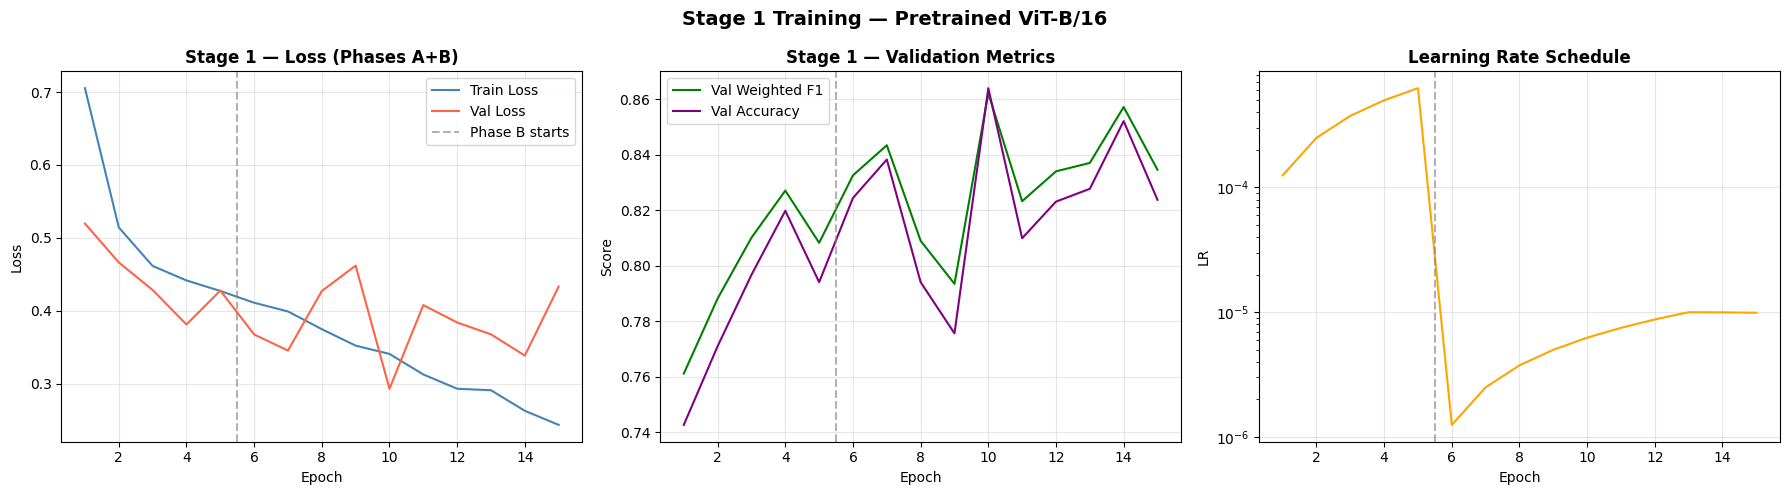

Saved: figures_pretrained/stage1_training_curves.png


In [12]:
total_s1_epochs = EPOCHS_WARMUP_S1 + EPOCHS_FINETUNE_S1
epochs_range = range(1, total_s1_epochs + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(epochs_range, history_s1['train_loss'], label='Train Loss', color='steelblue')
axes[0].plot(epochs_range, history_s1['val_loss'],   label='Val Loss',   color='tomato')
axes[0].axvline(EPOCHS_WARMUP_S1 + 0.5, color='gray', linestyle='--', alpha=0.6, label='Phase B starts')
axes[0].set_title('Stage 1 — Loss (Phases A+B)', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history_s1['val_f1'],  label='Val Weighted F1', color='green')
axes[1].plot(epochs_range, history_s1['val_acc'], label='Val Accuracy',    color='purple')
axes[1].axvline(EPOCHS_WARMUP_S1 + 0.5, color='gray', linestyle='--', alpha=0.6)
axes[1].set_title('Stage 1 — Validation Metrics', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(epochs_range, history_s1['lr'], color='orange')
axes[2].axvline(EPOCHS_WARMUP_S1 + 0.5, color='gray', linestyle='--', alpha=0.6)
axes[2].set_title('Learning Rate Schedule', fontweight='bold')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('LR')
axes[2].set_yscale('log'); axes[2].grid(True, alpha=0.3)

plt.suptitle('Stage 1 Training — Pretrained ViT-B/16', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'stage1_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures_pretrained/stage1_training_curves.png')


## 7. Stage 2 Training (MEL / BCC / AKIEC)

**Phase C** — backbone + `stage1_head` frozen, train `stage2_head` only.  
**Phase D** — unfreeze backbone with `stage2_head`, `stage1_head` stays frozen (protects Stage 1 performance).

In [13]:
checkpoint = torch.load(CHECKPOINTS_DIR / 'best_stage1_pretrained.pt', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
print(f'Loaded best Stage 1 checkpoint ({checkpoint["phase"]}, epoch {checkpoint["epoch"]}, '
      f'Val F1={checkpoint["val_f1"]:.4f})')

# Freeze backbone + stage1_head so only stage2_head updates during Phase C
for p in model.backbone.parameters():
    p.requires_grad = False
for p in model.stage1_head.parameters():
    p.requires_grad = False
# stage2_head stays trainable

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters for Phase C: {trainable:,}  (stage2_head only)')


Loaded best Stage 1 checkpoint (Phase B (S1 fine-tune), epoch 5, Val F1=0.8622)
Trainable parameters for Phase C: 3,843  (stage2_head only)


In [14]:
def train_one_epoch_stage2(model, loader, optimizer, scheduler, scaler, criterion):
    model.train()
    epoch_loss, num_samples = 0.0, 0
    optimizer.zero_grad()
    accum_count = 0
    for step, (imgs, _, s2_labels) in enumerate(loader):
        mask = s2_labels >= 0
        if mask.sum() == 0:
            continue
        imgs      = imgs[mask].to(device, non_blocking=True)
        s2_labels = s2_labels[mask].to(device, non_blocking=True)
        with autocast():
            _, logits2 = model(imgs)
            loss = criterion(logits2, s2_labels) / ACCUM_STEPS
        scaler.scale(loss).backward()
        accum_count += 1
        if accum_count % ACCUM_STEPS == 0 or (step + 1) == len(loader):
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            scheduler.step()
        epoch_loss  += loss.item() * ACCUM_STEPS * len(imgs)
        num_samples += len(imgs)
    return epoch_loss / max(num_samples, 1)


def run_stage2_phase(phase_name, epochs, optimizer, scheduler, history, best_f1, ckpt_name):
    scaler = GradScaler()
    criterion = nn.CrossEntropyLoss(weight=s2_weights)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'\n=== {phase_name} ===  trainable params: {trainable:,}')
    for epoch in range(1, epochs + 1):
        tr_loss = train_one_epoch_stage2(model, train_loader, optimizer, scheduler, scaler, criterion)
        val_loss, val_f1, val_acc, _, _ = validate_stage2(model, val_loader)
        current_lr = optimizer.param_groups[0]['lr']

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(val_loss)
        history['val_f1'].append(val_f1)
        history['val_acc'].append(val_acc)

        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save({
                'phase': phase_name, 'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'val_f1': val_f1,
            }, CHECKPOINTS_DIR / ckpt_name)

        print(f'[{phase_name}] Ep {epoch:2d}/{epochs} | '
              f'Train {tr_loss:.4f} | Val {val_loss:.4f} | '
              f'F1 {val_f1:.4f} | Acc {val_acc:.4f} | LR {current_lr:.2e}')
    return best_f1


In [15]:
history_s2 = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'val_acc': []}
best_s2_f1 = 0.0

# ---- Phase C: stage2_head only (backbone + stage1_head frozen) ----
optimizer_C = optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LR_WARMUP, weight_decay=WEIGHT_DECAY,
)
scheduler_C = get_lr_scheduler(optimizer_C, WARMUP_EPOCHS, EPOCHS_WARMUP_S2, len(train_loader))
best_s2_f1 = run_stage2_phase(
    'Phase C (S2 head-only)', EPOCHS_WARMUP_S2,
    optimizer_C, scheduler_C, history_s2, best_s2_f1,
    ckpt_name='best_stage2_pretrained.pt',
)

# ---- Phase D: unfreeze backbone + stage2_head (stage1_head stays frozen) ----
model.unfreeze_backbone()
# stage1_head stays frozen to protect its learned weights; stage2_head is trainable.
optimizer_D = optim.AdamW([
    {'params': model.backbone.parameters(),    'lr': LR_BACKBONE},
    {'params': model.stage2_head.parameters(), 'lr': LR_HEAD},
], weight_decay=WEIGHT_DECAY)
scheduler_D = get_lr_scheduler(optimizer_D, WARMUP_EPOCHS, EPOCHS_FINETUNE_S2, len(train_loader))
best_s2_f1 = run_stage2_phase(
    'Phase D (S2 fine-tune)', EPOCHS_FINETUNE_S2,
    optimizer_D, scheduler_D, history_s2, best_s2_f1,
    ckpt_name='best_stage2_pretrained.pt',
)

print(f'\nBest Stage 2 Val Weighted F1 (across phases C+D): {best_s2_f1:.4f}')
print('Checkpoint: checkpoints_pretrained/best_stage2_pretrained.pt')



=== Phase C (S2 head-only) ===  trainable params: 3,843
[Phase C (S2 head-only)] Ep  1/5 | Train 1.2400 | Val 0.8699 | F1 0.5062 | Acc 0.5811 | LR 1.04e-04
[Phase C (S2 head-only)] Ep  2/5 | Train 0.8258 | Val 0.6067 | F1 0.7566 | Acc 0.7670 | LR 2.05e-04
[Phase C (S2 head-only)] Ep  3/5 | Train 0.6325 | Val 0.5137 | F1 0.7809 | Acc 0.7906 | LR 3.11e-04
[Phase C (S2 head-only)] Ep  4/5 | Train 0.5618 | Val 0.4767 | F1 0.8058 | Acc 0.7994 | LR 4.15e-04
[Phase C (S2 head-only)] Ep  5/5 | Train 0.5238 | Val 0.4304 | F1 0.8115 | Acc 0.8112 | LR 5.18e-04

=== Phase D (S2 fine-tune) ===  trainable params: 85,802,499
[Phase D (S2 fine-tune)] Ep  1/10 | Train 0.4733 | Val 0.3894 | F1 0.8266 | Acc 0.8319 | LR 1.01e-06
[Phase D (S2 fine-tune)] Ep  2/10 | Train 0.4326 | Val 0.3579 | F1 0.8411 | Acc 0.8407 | LR 2.08e-06
[Phase D (S2 fine-tune)] Ep  3/10 | Train 0.3814 | Val 0.3124 | F1 0.8564 | Acc 0.8614 | LR 3.11e-06
[Phase D (S2 fine-tune)] Ep  4/10 | Train 0.3780 | Val 0.3944 | F1 0.8517 | Ac

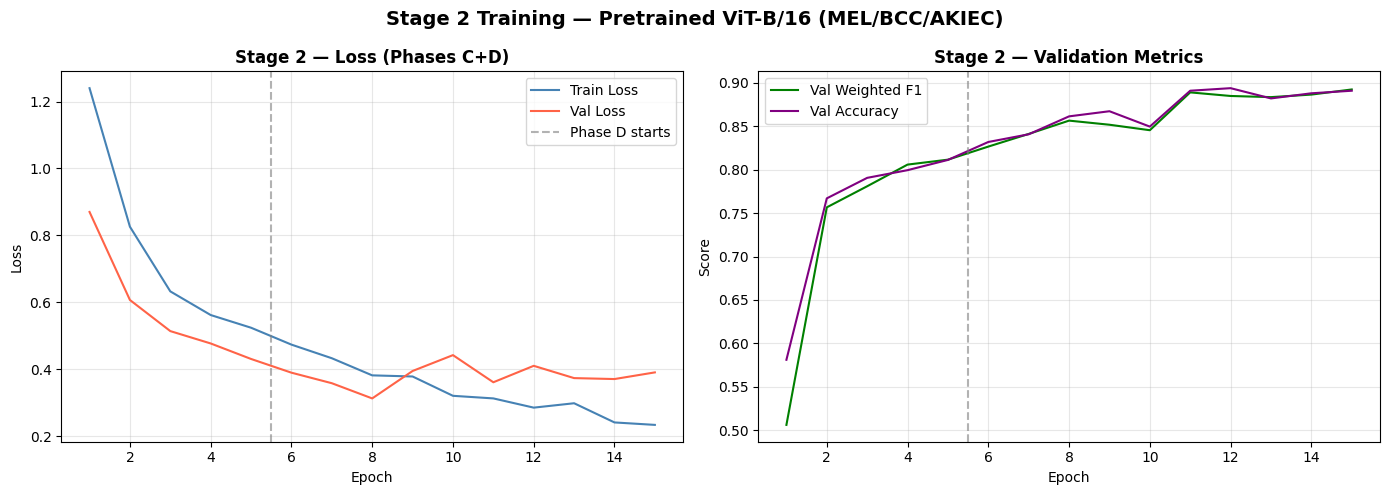

Saved: figures_pretrained/stage2_training_curves.png


In [16]:
total_s2_epochs = EPOCHS_WARMUP_S2 + EPOCHS_FINETUNE_S2
epochs_range = range(1, total_s2_epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history_s2['train_loss'], label='Train Loss', color='steelblue')
axes[0].plot(epochs_range, history_s2['val_loss'],   label='Val Loss',   color='tomato')
axes[0].axvline(EPOCHS_WARMUP_S2 + 0.5, color='gray', linestyle='--', alpha=0.6, label='Phase D starts')
axes[0].set_title('Stage 2 — Loss (Phases C+D)', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history_s2['val_f1'],  label='Val Weighted F1', color='green')
axes[1].plot(epochs_range, history_s2['val_acc'], label='Val Accuracy',    color='purple')
axes[1].axvline(EPOCHS_WARMUP_S2 + 0.5, color='gray', linestyle='--', alpha=0.6)
axes[1].set_title('Stage 2 — Validation Metrics', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle('Stage 2 Training — Pretrained ViT-B/16 (MEL/BCC/AKIEC)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'stage2_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures_pretrained/stage2_training_curves.png')


## 8. Evaluation on Held-Out Test Set

In [17]:
# For fair evaluation we run each stage with the checkpoint where that stage's
# head was best. Stage 1 uses best_stage1_pretrained.pt (backbone + stage1_head
# from phases A+B). Stage 2 uses best_stage2_pretrained.pt (backbone + stage2_head
# from phases C+D — note stage1_head in this checkpoint was NOT updated after
# phase B so its predictions should still be valid, but we prefer stage1's own
# checkpoint to be safe).

def _load(ckpt_name):
    ckpt = torch.load(CHECKPOINTS_DIR / ckpt_name, map_location=device)
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()
    print(f'Loaded {ckpt_name} ({ckpt["phase"]}, epoch {ckpt["epoch"]}, '
          f'Val F1={ckpt["val_f1"]:.4f})')

print('Evaluation checkpoint loader ready.')


Evaluation checkpoint loader ready.


In [18]:
@torch.no_grad()
def collect_stage1_preds(model, loader):
    model.eval()
    s1_true, s1_pred, s1_probs = [], [], []
    for imgs, s1_labels, _ in loader:
        imgs = imgs.to(device)
        with autocast():
            logits1, _ = model(imgs)
        probs1 = torch.softmax(logits1, dim=1)
        s1_true.extend(s1_labels.numpy())
        s1_pred.extend(probs1.argmax(dim=1).cpu().numpy())
        s1_probs.extend(probs1.cpu().numpy())
    return np.array(s1_true), np.array(s1_pred), np.array(s1_probs)


@torch.no_grad()
def collect_stage2_preds(model, loader):
    model.eval()
    s2_true, s2_pred, s2_probs = [], [], []
    for imgs, _, s2_labels in loader:
        imgs = imgs.to(device)
        with autocast():
            _, logits2 = model(imgs)
        probs2 = torch.softmax(logits2, dim=1)
        mask = s2_labels >= 0
        if mask.sum() == 0:
            continue
        s2_true.extend(s2_labels[mask].numpy())
        s2_pred.extend(probs2[mask.to(device)].argmax(dim=1).cpu().numpy())
        s2_probs.extend(probs2[mask.to(device)].cpu().numpy())
    return np.array(s2_true), np.array(s2_pred), np.array(s2_probs)


# Stage 1 predictions from stage 1 checkpoint
_load('best_stage1_pretrained.pt')
s1_true, s1_pred, s1_probs = collect_stage1_preds(model, test_loader)
print(f'Stage 1 test samples: {len(s1_true)}')

# Stage 2 predictions from stage 2 checkpoint
_load('best_stage2_pretrained.pt')
s2_true, s2_pred, s2_probs = collect_stage2_preds(model, test_loader)
print(f'Stage 2 test samples (malignant only): {len(s2_true)}')


Loaded best_stage1_pretrained.pt (Phase B (S1 fine-tune), epoch 5, Val F1=0.8622)
Stage 1 test samples: 1519
Loaded best_stage2_pretrained.pt (Phase D (S2 fine-tune), epoch 10, Val F1=0.8923)
Stage 2 test samples (malignant only): 259


In [19]:
def compute_all_metrics(y_true, y_pred, y_probs, class_names, stage_name):
    n_classes = len(class_names)
    acc  = accuracy_score(y_true, y_pred)
    wf1  = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)

    sep = '=' * 60
    print()
    print(sep)
    print(f' {stage_name} — Test Set Results (Pretrained ViT-B/16)')
    print(sep)
    print(f'  Overall Accuracy       : {acc:.4f}')
    print(f'  Weighted F1 Score      : {wf1:.4f}')
    print(f'  Weighted Precision     : {prec:.4f}')
    print(f'  Weighted Recall (Sens) : {rec:.4f}')

    print('  Per-class metrics:')
    print(classification_report(y_true, y_pred, target_names=class_names,
                                digits=4, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))
    print('  Specificity per class:')
    for i, cls in enumerate(class_names):
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0
        print(f'    {cls:8s}: {spec:.4f}')
    return acc, wf1, prec, rec, cm


s1_acc, s1_wf1, s1_prec, s1_rec, s1_cm = compute_all_metrics(
    s1_true, s1_pred, s1_probs, ['Benign', 'Malignant'], 'STAGE 1'
)



 STAGE 1 — Test Set Results (Pretrained ViT-B/16)
  Overall Accuracy       : 0.8683
  Weighted F1 Score      : 0.8711
  Weighted Precision     : 0.8748
  Weighted Recall (Sens) : 0.8683
  Per-class metrics:
              precision    recall  f1-score   support

      Benign     0.9309    0.9087    0.9197      1260
   Malignant     0.6021    0.6718    0.6350       259

    accuracy                         0.8683      1519
   macro avg     0.7665    0.7903    0.7774      1519
weighted avg     0.8748    0.8683    0.8711      1519

  Specificity per class:
    Benign  : 0.6718
    Malignant: 0.9087


In [20]:
s2_acc, s2_wf1, s2_prec, s2_rec, s2_cm = compute_all_metrics(
    s2_true, s2_pred, s2_probs, MAL_SUBCLASS_NAMES, 'STAGE 2'
)



 STAGE 2 — Test Set Results (Pretrained ViT-B/16)
  Overall Accuracy       : 0.8880
  Weighted F1 Score      : 0.8894
  Weighted Precision     : 0.8931
  Weighted Recall (Sens) : 0.8880
  Per-class metrics:
              precision    recall  f1-score   support

         MEL     0.9650    0.9139    0.9388       151
         BCC     0.8000    0.9032    0.8485        62
       AKIEC     0.7826    0.7826    0.7826        46

    accuracy                         0.8880       259
   macro avg     0.8492    0.8666    0.8566       259
weighted avg     0.8931    0.8880    0.8894       259

  Specificity per class:
    MEL     : 0.9537
    BCC     : 0.9289
    AKIEC   : 0.9531


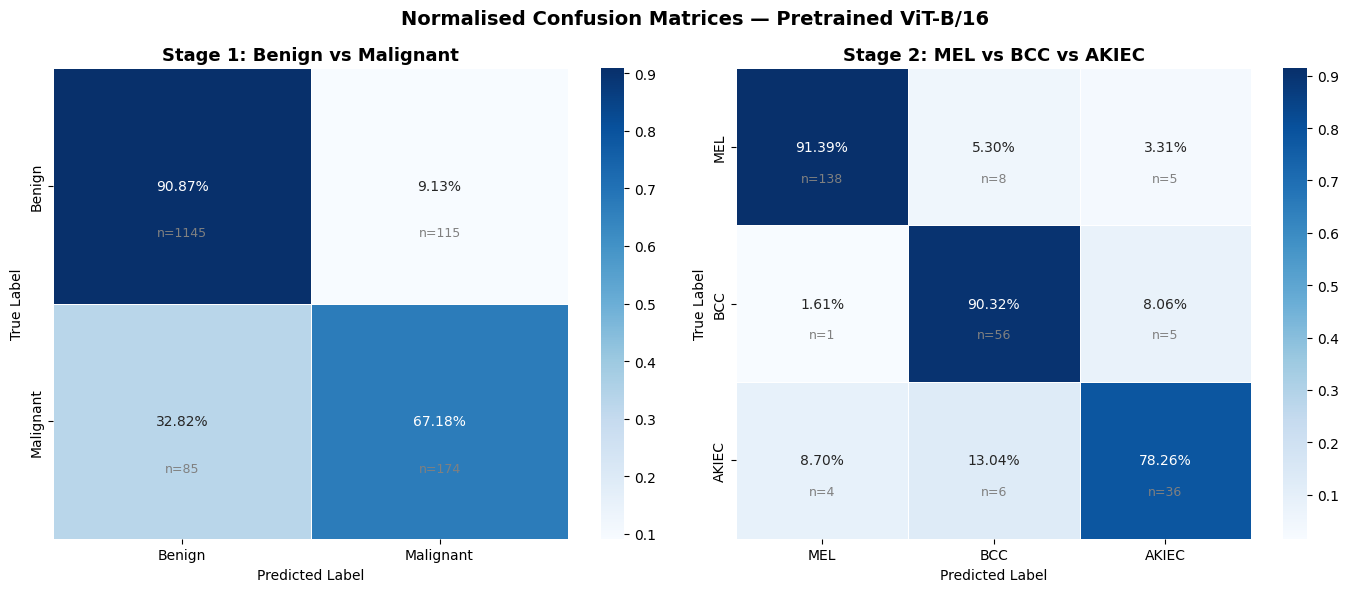

Saved: figures_pretrained/confusion_matrices.png


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (cm, labels, title) in zip(axes, [
    (s1_cm, ['Benign', 'Malignant'], 'Stage 1: Benign vs Malignant'),
    (s2_cm, MAL_SUBCLASS_NAMES,      'Stage 2: MEL vs BCC vs AKIEC'),
]):
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
                xticklabels=labels, yticklabels=labels,
                ax=ax, linewidths=0.5)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j + 0.5, i + 0.7, f'n={cm[i,j]}',
                    ha='center', va='center', fontsize=9, color='gray')
    ax.set_title(title, fontweight='bold', fontsize=13)
    ax.set_xlabel('Predicted Label'); ax.set_ylabel('True Label')

plt.suptitle('Normalised Confusion Matrices — Pretrained ViT-B/16',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures_pretrained/confusion_matrices.png')


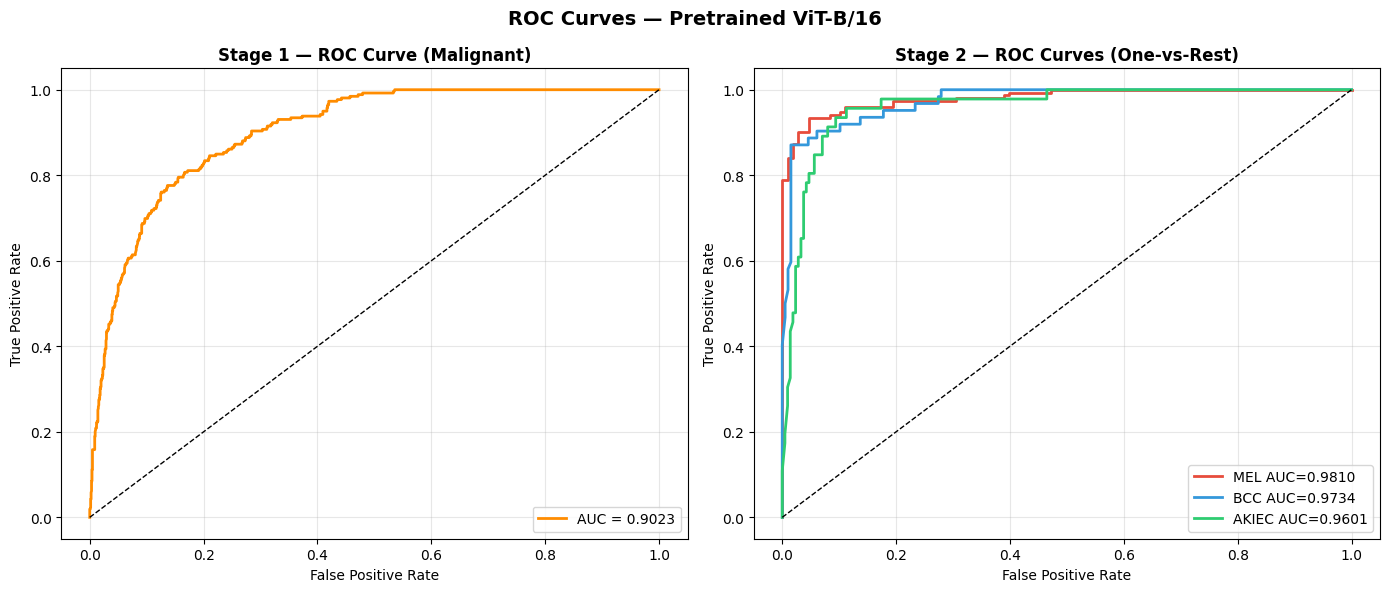

Saved: figures_pretrained/roc_curves.png


In [22]:
from sklearn.preprocessing import label_binarize

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Stage 1 ROC
ax = axes[0]
fpr, tpr, _ = roc_curve(s1_true, s1_probs[:, 1])
s1_auc = auc(fpr, tpr)
ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {s1_auc:.4f}')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('Stage 1 — ROC Curve (Malignant)', fontweight='bold')
ax.legend(loc='lower right'); ax.grid(True, alpha=0.3)

# Stage 2 ROC (OvR)
ax = axes[1]
colors = ['#e74c3c', '#3498db', '#2ecc71']
s2_binarized = label_binarize(s2_true, classes=[0, 1, 2])
for i, (cls_name, color) in enumerate(zip(MAL_SUBCLASS_NAMES, colors)):
    fpr, tpr, _ = roc_curve(s2_binarized[:, i], s2_probs[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{cls_name} AUC={roc_auc:.4f}')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('Stage 2 — ROC Curves (One-vs-Rest)', fontweight='bold')
ax.legend(loc='lower right'); ax.grid(True, alpha=0.3)

plt.suptitle('ROC Curves — Pretrained ViT-B/16', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures_pretrained/roc_curves.png')


## 9. Summary Metrics (for cross-model comparison)

In [23]:
pretrained_vit_results = {
    'stage1_accuracy'       : s1_acc,
    'stage1_weighted_f1'    : s1_wf1,
    'stage1_weighted_prec'  : s1_prec,
    'stage1_weighted_recall': s1_rec,
    'stage1_auc'            : s1_auc,
    'stage2_accuracy'       : s2_acc,
    'stage2_weighted_f1'    : s2_wf1,
    'stage2_weighted_prec'  : s2_prec,
    'stage2_weighted_recall': s2_rec,
}

summary_df = pd.DataFrame({
    'Metric': list(pretrained_vit_results.keys()),
    'Pretrained ViT-B/16': [f'{v:.4f}' for v in pretrained_vit_results.values()],
})
print('\n' + '=' * 60)
print(' FINAL TEST-SET METRICS — Pretrained ViT-B/16')
print('=' * 60)
print(summary_df.to_string(index=False))

# Persist for later cross-model comparison (vs MobileNetV2, from-scratch ViT)
with open(FIGURES_DIR / 'pretrained_vit_metrics.json', 'w') as f:
    json.dump(pretrained_vit_results, f, indent=2)
print('\nSaved metrics dict to figures_pretrained/pretrained_vit_metrics.json')



 FINAL TEST-SET METRICS — Pretrained ViT-B/16
                Metric Pretrained ViT-B/16
       stage1_accuracy              0.8683
    stage1_weighted_f1              0.8711
  stage1_weighted_prec              0.8748
stage1_weighted_recall              0.8683
            stage1_auc              0.9023
       stage2_accuracy              0.8880
    stage2_weighted_f1              0.8894
  stage2_weighted_prec              0.8931
stage2_weighted_recall              0.8880

Saved metrics dict to figures_pretrained/pretrained_vit_metrics.json


---
## 10. Pipeline Evaluation

End-to-end pipeline metrics: Stage 1 leakage rate, Stage 2 conditional accuracy, and overall pipeline recall.

In [24]:
import sys, os
sys.path.insert(0, str(Path('.').resolve()))
from evaluation import evaluate_stage1, evaluate_stage2, evaluate_pipeline


  STAGE 1 EVALUATION — Benign vs Malignant

  Stage 1 Classification Report
              precision    recall  f1-score   support

      Benign       0.93      0.91      0.92      1260
   Malignant       0.60      0.67      0.64       259

    accuracy                           0.87      1519
   macro avg       0.77      0.79      0.78      1519
weighted avg       0.87      0.87      0.87      1519

----------------------------------------
  *** PER-CLASS RECALL (PRIMARY METRIC) ***
----------------------------------------
  Benign        0.9087  ███████████████████████████
  Malignant     0.6718  ████████████████████

  Macro Recall:    0.7903
  Weighted Recall: 0.8683
----------------------------------------

Macro F1:    0.7774
Weighted F1: 0.8711
Accuracy:    0.8683
ROC-AUC (binary): 0.9023


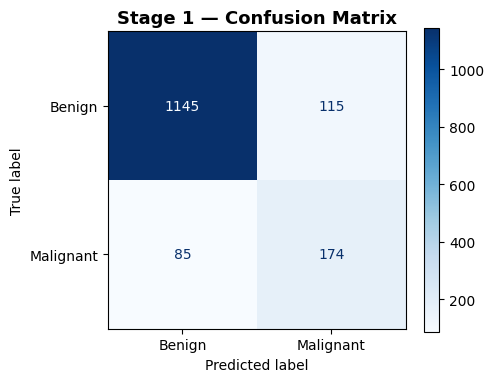

In [25]:
# Stage 1 extended metrics (adds Macro F1)
s1_results = evaluate_stage1(s1_true, s1_pred, s1_probs)


  STAGE 2 EVALUATION — Malignant Subtypes

  Stage 2 Classification Report
              precision    recall  f1-score   support

       akiec       0.97      0.91      0.94       151
         bcc       0.80      0.90      0.85        62
         mel       0.78      0.78      0.78        46

    accuracy                           0.89       259
   macro avg       0.85      0.87      0.86       259
weighted avg       0.89      0.89      0.89       259

----------------------------------------
  *** PER-CLASS RECALL (PRIMARY METRIC) ***
----------------------------------------
  akiec         0.9139  ███████████████████████████
  bcc           0.9032  ███████████████████████████
  mel           0.7826  ███████████████████████

  Macro Recall:    0.8666
  Weighted Recall: 0.8880
----------------------------------------

Macro F1:    0.8566
Weighted F1: 0.8894
Accuracy:    0.8880
ROC-AUC (macro, OvR): 0.9715


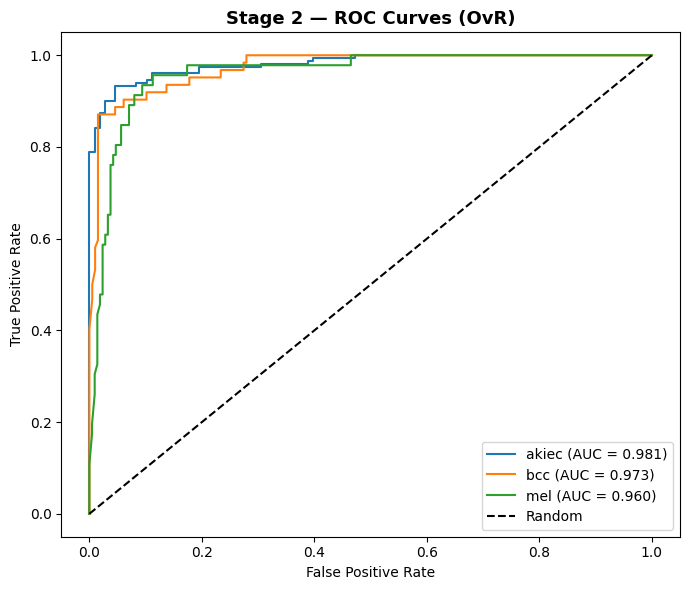

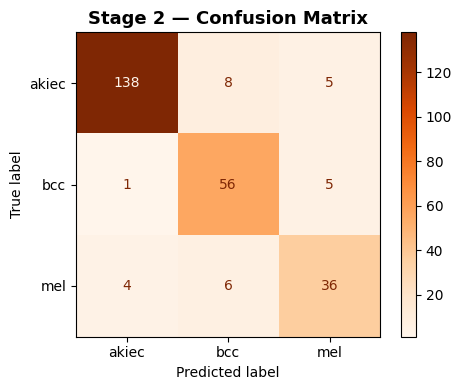

In [26]:
# Stage 2 extended metrics (adds Macro F1 + per-class recall)
s2_results = evaluate_stage2(s2_true, s2_pred, s2_probs)

In [27]:
# Collect Stage 2 predictions for pipeline evaluation
# Filters to images where Stage 1 predicted malignant (not just ground-truth malignant)
@torch.no_grad()
def run_pipeline_s2(model, loader):
    model.eval()
    s2_true_pl, s2_pred_pl = [], []
    _load('best_stage2_pretrained.pt')
    for imgs, s1_labels, s2_labels in loader:
        imgs = imgs.to(device)
        with autocast():
            logits1, logits2 = model(imgs)
        probs1 = torch.softmax(logits1, dim=1)
        probs2 = torch.softmax(logits2, dim=1)
        pred1  = probs1.argmax(dim=1).cpu()
        pred2  = probs2.argmax(dim=1).cpu()
        mask = (pred1 == 1) & (s2_labels >= 0)
        if mask.sum() > 0:
            s2_true_pl.extend(s2_labels[mask].numpy())
            s2_pred_pl.extend(pred2[mask].numpy())
    return np.array(s2_true_pl), np.array(s2_pred_pl)

s2_true_pipeline, s2_pred_pipeline = run_pipeline_s2(model, test_loader)
print(f'Stage 1 TPs reaching Stage 2: {len(s2_true_pipeline)}')

Loaded best_stage2_pretrained.pt (Phase D (S2 fine-tune), epoch 10, Val F1=0.8923)
Stage 1 TPs reaching Stage 2: 150


In [28]:
pipeline_results = evaluate_pipeline(s1_true, s1_pred, s2_true_pipeline, s2_pred_pipeline)


  PIPELINE EVALUATION — Stage 1 → Stage 2

Total malignant cases in test set:     259
Correctly flagged by Stage 1 (TP):     174
Missed by Stage 1 (FN — LEAKAGE):      85
Stage 1 Recall (malignant):            0.6718
Stage 1 Leakage Rate:                  0.3282

Cases reaching Stage 2:                150
Correctly classified by Stage 2:       135
Stage 2 Conditional Accuracy:          0.9000

*** OVERALL PIPELINE RECALL:            0.5212 ***
    (of 259 malignant cases, 135 got the correct final diagnosis)

Pipeline Accuracy (all test images):   0.8427
    (1145 benign correct + 135 malignant fully correct out of 1519 total)

----------------------------------------


In [29]:
# ViT efficiency summary
import time

ckpt_path = CHECKPOINTS_DIR / 'best_stage2_pretrained.pt'
size_mb = os.path.getsize(ckpt_path) / (1024 * 1024) if ckpt_path.exists() else None

model_cpu = model.cpu().eval()
dummy_img = torch.zeros(1, 3, 224, 224)
with torch.no_grad():
    for _ in range(10): model_cpu(dummy_img)
    t0 = time.time()
    for _ in range(100): model_cpu(dummy_img)
    avg_ms = (time.time() - t0) / 100 * 1000
model.to(device)

total_params = sum(p.numel() for p in model.parameters())
print("=" * 45)
print("  Pretrained ViT-B/16 EFFICIENCY SUMMARY")
print("=" * 45)
print(f"  Parameters:        {total_params:,}  (~{total_params/1e6:.1f}M)")
if size_mb:
    print(f"  Model size:        {size_mb:.1f} MB")
print(f"  Inference time:    {avg_ms:.1f} ms/image (CPU, single image)")
print("=" * 45)

  Pretrained ViT-B/16 EFFICIENCY SUMMARY
  Parameters:        85,805,573  (~85.8M)
  Model size:        327.4 MB
  Inference time:    102.3 ms/image (CPU, single image)


---
## 11. Explainability Comparison: ViT Attention Rollout vs MobileNetV2 Grad-CAM

We compare how each model explains its decisions on the same three malignant test images.

- **MobileNetV2** uses **Grad-CAM** (gradient-weighted class activation maps) on its last convolutional block.
- **ViT-B/16** uses **Attention Rollout** (Abnar & Zuidema, 2020): attention matrices from all 12 transformer blocks are composed via matrix multiplication (with residual connections added as identity) so that the CLS token's effective attention to each of the 196 image patches is propagated end-to-end.

The comparison reveals whether the two architectures focus on the same skin lesion regions despite their fundamentally different inductive biases.

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import torchvision.models as tvm

# ── Attention Rollout for torchvision ViT-B/16 ──────────────────────────────
def attention_rollout_vit(vit_model, img_tensor, device):
    """Compute Attention Rollout (Abnar & Zuidema 2020) for torchvision ViT-B/16."""
    vit_model.eval()
    attention_list = []

    def make_hook():
        def hook(module, inputs, output):
            # inputs[0] = query = key = value (self-attention in ViT)
            q = inputs[0]
            with torch.no_grad():
                _, attn_w = F.multi_head_attention_forward(
                    q, q, q,
                    embed_dim_to_check=module.embed_dim,
                    num_heads=module.num_heads,
                    in_proj_weight=module.in_proj_weight,
                    in_proj_bias=module.in_proj_bias,
                    bias_k=module.bias_k,
                    bias_v=module.bias_v,
                    add_zero_attn=module.add_zero_attn,
                    dropout_p=0.0,
                    out_proj_weight=module.out_proj.weight,
                    out_proj_bias=module.out_proj.bias,
                    training=False,
                    need_weights=True,
                    average_attn_weights=False,
                )
            attention_list.append(attn_w.detach().cpu())  # (1, heads, N, N)
        return hook

    hooks = []
    for block in vit_model.backbone.encoder.layers:
        hooks.append(block.self_attention.register_forward_hook(make_hook()))

    with torch.no_grad():
        _ = vit_model(img_tensor.to(device))

    for h in hooks:
        h.remove()

    # Rollout: compose all 12 attention layers, adding residual identity at each step
    num_tokens = 197  # 196 patches + 1 CLS token
    eye = torch.eye(num_tokens)
    rollout = eye.clone()
    for attn in attention_list:           # attn: (1, heads, N, N)
        attn_avg = attn[0].mean(dim=0)    # average over heads -> (N, N)
        attn_aug = attn_avg + eye         # add residual connection
        attn_aug = attn_aug / attn_aug.sum(dim=-1, keepdim=True)  # re-normalise
        rollout  = attn_aug @ rollout

    cls_attn = rollout[0, 1:].numpy()    # CLS token's attention to 196 patches
    mask = cls_attn.reshape(14, 14)
    mask = (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)
    # Upsample 14x14 patch grid to 224x224 for overlay
    mask_pil = Image.fromarray((mask * 255).astype('uint8')).resize((224, 224), resample=Image.BILINEAR)
    mask = np.array(mask_pil) / 255.0
    return mask


# ── Load MobileNetV2 Stage 1 checkpoint ──────────────────────────────────────
mobilenet = tvm.mobilenet_v2(weights=None)
mobilenet.classifier = nn.Sequential(nn.Dropout(p=0.2), nn.Linear(1280, 2))
mobilenet.load_state_dict(torch.load('best_model_stage1.pt', map_location=device))
mobilenet = mobilenet.to(device).eval()
print("MobileNetV2 Stage 1 loaded.")

# ── Reload best ViT Stage 1 weights ──────────────────────────────────────────
def _load_ckpt(path):
    ckpt = torch.load(path, map_location=device)
    state = ckpt['model_state_dict'] if 'model_state_dict' in ckpt else ckpt
    model.load_state_dict(state)

_load_ckpt(CHECKPOINTS_DIR / 'best_stage1_pretrained.pt')
model.eval()
print("Pretrained ViT Stage 1 loaded.")


# ── Select 3 malignant test images (same ordering as MobileNetV2 Grad-CAM) ───
malignant_test = test_df[test_df['stage1_label'] == 1].head(3)

# ── Build side-by-side comparison figure ─────────────────────────────────────
cam = GradCAM(model=mobilenet, target_layers=[mobilenet.features[-1]])
targets_cls = [ClassifierOutputTarget(1)]

fig, axes = plt.subplots(3, 3, figsize=(15, 13))
col_titles = ['Original Image', 'MobileNetV2 Grad-CAM', 'ViT-B/16 Attention Rollout']
for ax, title in zip(axes[0], col_titles):
    ax.set_title(title, fontsize=13, fontweight='bold', pad=8)

for row_idx, (_, row) in enumerate(malignant_test.iterrows()):
    img_pil = Image.open(row['filepath']).convert('RGB').resize((224, 224))
    img_np  = np.array(img_pil) / 255.0
    img_t   = val_transform(img_pil).unsqueeze(0)

    # MobileNetV2 Grad-CAM
    grayscale = cam(input_tensor=img_t.to(device), targets=targets_cls)
    cam_img   = show_cam_on_image(img_np.astype(np.float32), grayscale[0], use_rgb=True)

    # ViT Attention Rollout
    attn_mask = attention_rollout_vit(model, img_t, device)
    attn_img  = show_cam_on_image(img_np.astype(np.float32), attn_mask, use_rgb=True)

    dx_label = row['dx'].upper()
    axes[row_idx, 0].imshow(img_pil);   axes[row_idx, 0].axis('off')
    axes[row_idx, 0].set_ylabel(dx_label, fontsize=12, fontweight='bold',
                                rotation=0, labelpad=40, va='center')
    axes[row_idx, 1].imshow(cam_img);   axes[row_idx, 1].axis('off')
    axes[row_idx, 2].imshow(attn_img);  axes[row_idx, 2].axis('off')

plt.suptitle(
    'Explainability Comparison: MobileNetV2 Grad-CAM vs ViT-B/16 Attention Rollout\n'
    '(Malignant Test Cases)',
    fontsize=14, fontweight='bold', y=1.01
)
plt.tight_layout()
out_path = Path('figures_pretrained') / 'vit_vs_mobilenet_explainability.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved comparison figure to {out_path}")